# Part 3A：三种低波动行业组合的构建

## 题目重述
用 **1995/01 – 2004/12**（120 个月，"种子期"）49 个行业的月度收益估计协方差矩阵 $\Sigma$，站在 **2004/12/31** 这一天构建三个组合：

| # | 组合 | 规则 | 求解方式 |
|---|---|---|---|
| ① | 最小方差（可做空） | $\min w^\top\Sigma w$，$\sum w_i = 1$ | 解析解 |
| ② | 最小方差（只做多） | 同上，再加 $w_i \ge 0$ | 二次规划（数值解） |
| ③ | 逆波动率 | $w_i \propto 1/\sigma_i$ | 公式，不需要优化 |


## 本 notebook 的输出

| 文件 | 内容 |
|---|---|
| `output/tables/tab_3A_weights.csv` | 权重表原始数值（小数，含合计行） |
| `output/tables/tab_3A_weights.xlsx` | 已标好绿/红色的权重表，可复制进 Word |
| `output/figures/fig_3A_weights_table.png` | 报告用的权重表图（两栏排版） |
| `output/figures/fig_3A_weight_profile.png` | 三种组合的权重分布对比图 |


## 1. 环境设置

从当前目录往上找到项目根目录（含 `src/config.py` 的那一层），这样不管从哪里打开 notebook 都能运行。路径、时间段和图表风格统一用组里的 `src/config.py` 和 `src/utils.py`。

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cvxpy as cp
from scipy.optimize import minimize

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config, utils

config.apply_style()
pd.set_option("display.max_rows", 60)
print("项目根目录:", ROOT)
print("数据文件  :", config.FILE_PART3.name)
print("种子期    :", config.PERIODS["3_seed"])

项目根目录: e:\subjects\研一\Portfolio Theory and Investment\Final Project
数据文件  : class project data (part 3 - pf construction).xlsx
种子期    : ('1995-01', '2004-12')


## 2. 读取与检查数据

需注意：
- 单位是**百分比**（7.95 = 7.95%），按组内约定转成小数；
- 缺失值用 `-99.99` 或 `-999` 表示，要确认分析期内没有；
- 只读取紧跟在表头下面、连续的 `YYYYMM` 行，避免误读下面可能接着的其他数据块。

In [2]:
raw = pd.read_excel(config.FILE_PART3, header=None)

# 表头行：第二列是 'Agric' 的那一行
hdr = raw.index[raw.iloc[:, 1].astype(str).str.strip().eq("Agric")][0]
codes = raw.iloc[hdr, 1:].astype(str).str.strip().tolist()

body = raw.iloc[hdr + 1:, :].copy()
body.columns = ["month"] + codes
is_month = body["month"].astype(str).str.strip().str.fullmatch(r"\d{6}(\.0)?").to_numpy()
n_rows = len(is_month) if is_month.all() else int(np.argmin(is_month))   # 第一个非月份行之前
body = body.iloc[:n_rows].set_index("month")

ret_pct = utils.to_monthly_index(body.apply(pd.to_numeric))
rets = utils.pct_to_decimal(ret_pct)            # 小数收益，行 = 当月实现的收益

print(f"表头所在行（0 起）: {hdr}")
print(f"行业数: {rets.shape[1]}，月份数: {rets.shape[0]}，区间: {rets.index[0]} ~ {rets.index[-1]}")
print("缺失值标记 -99.99 / -999 的个数:", int(ret_pct.isin([-99.99, -999]).sum().sum()))
print("NaN 个数:", int(rets.isna().sum().sum()))
assert rets.shape[1] == 49
assert not ret_pct.isin([-99.99, -999]).any().any() and not rets.isna().any().any()
rets.iloc[:3, :8]

表头所在行（0 起）: 11
行业数: 49，月份数: 343，区间: 1995-01 ~ 2023-07
缺失值标记 -99.99 / -999 的个数: 0
NaN 个数: 0


,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books
month,,,,,,,,
1995-01,0.0795,0.0201,0.0620,0.0282,0.0459,0.0005,0.0785,0.0022
1995-02,-0.0513,0.0139,0.0511,0.0487,-0.0125,0.0424,0.0396,0.0493
1995-03,0.0611,0.0364,0.0174,0.0244,0.0593,0.0211,0.0453,0.0134


### 行业名称对照

数据里只有 Fama-French 的行业缩写。下面的对照表只用来帮助阅读：中文名在 notebook 里看，英文简称用在报告的图表里。

In [3]:
NAMES = {  # 代码: (报告用英文简称, 中文)
    "Agric": ("Agriculture", "农业"),            "Food":  ("Food products", "食品"),
    "Soda":  ("Candy & soda", "糖果与软饮"),       "Beer":  ("Beer & liquor", "啤酒与烈酒"),
    "Smoke": ("Tobacco", "烟草"),                 "Toys":  ("Recreation", "休闲用品/玩具"),
    "Fun":   ("Entertainment", "娱乐"),           "Books": ("Printing & publishing", "印刷出版"),
    "Hshld": ("Consumer goods", "日用消费品"),      "Clths": ("Apparel", "服装"),
    "Hlth":  ("Healthcare services", "医疗服务"),  "MedEq": ("Medical equipment", "医疗器械"),
    "Drugs": ("Pharmaceuticals", "制药"),         "Chems": ("Chemicals", "化工"),
    "Rubbr": ("Rubber & plastics", "橡胶塑料"),     "Txtls": ("Textiles", "纺织"),
    "BldMt": ("Construction materials", "建材"),  "Cnstr": ("Construction", "建筑"),
    "Steel": ("Steel works", "钢铁"),             "FabPr": ("Fabricated products", "金属制品"),
    "Mach":  ("Machinery", "机械"),               "ElcEq": ("Electrical equipment", "电气设备"),
    "Autos": ("Autos & trucks", "汽车与卡车"),      "Aero":  ("Aircraft", "飞机制造"),
    "Ships": ("Ships & rail equipment", "船舶与铁路设备"), "Guns": ("Defense", "国防军工"),
    "Gold":  ("Precious metals", "贵金属"),        "Mines": ("Non-precious mining", "非贵金属采矿"),
    "Coal":  ("Coal", "煤炭"),                     "Oil":   ("Petroleum & natural gas", "石油天然气"),
    "Util":  ("Utilities", "公用事业"),            "Telcm": ("Communication", "通信"),
    "PerSv": ("Personal services", "个人服务"),     "BusSv": ("Business services", "商业服务"),
    "Hardw": ("Computer hardware", "计算机硬件"),    "Softw": ("Computer software", "软件"),
    "Chips": ("Electronic equipment", "电子设备/芯片"), "LabEq": ("Measuring & control equip.", "测量与控制设备"),
    "Paper": ("Business supplies", "商业用品/纸业"), "Boxes": ("Shipping containers", "包装容器"),
    "Trans": ("Transportation", "交通运输"),        "Whlsl": ("Wholesale", "批发"),
    "Rtail": ("Retail", "零售"),                   "Meals": ("Restaurants & hotels", "餐饮酒店"),
    "Banks": ("Banking", "银行"),                  "Insur": ("Insurance", "保险"),
    "RlEst": ("Real estate", "房地产"),             "Fin":   ("Trading", "金融交易"),
    "Other": ("Other", "其他"),
}
assert set(NAMES) == set(rets.columns), set(rets.columns) ^ set(NAMES)
EN = {k: v[0] for k, v in NAMES.items()}
CN = {k: v[1] for k, v in NAMES.items()}
print("49 个行业代码与对照表一一对应 ✓")

49 个行业代码与对照表一一对应 ✓


## 3. 估计协方差矩阵（种子期 1995/01 – 2004/12）

用 120 个月 × 49 个行业的月度收益算样本协方差矩阵 $\Sigma$（49×49）。

两点检查：

- **正定性**：最小特征值必须大于 0，否则 $\Sigma^{-1}$ 不存在，最小方差问题也没有唯一解。这里样本数 120 > 资产数 49，正常情况下一定满足；
- **条件数**：最大特征值 / 最小特征值。条件数越大，$\Sigma^{-1}$ 越"敏感"，数据里一点小误差就会导致权重大幅变化。这正是 3B/3C 要讨论的"优化放大估计误差"的根源。

In [4]:
seed = utils.select_period(rets, "3_seed")
assert seed.shape == (120, 49), seed.shape
print(f"种子期: {seed.index[0]} ~ {seed.index[-1]}，{seed.shape[0]} 个月 × {seed.shape[1]} 个行业")

Sigma = seed.cov()                       # 样本协方差（ddof=1），月度
S = Sigma.to_numpy()
eig = np.linalg.eigvalsh(S)
print(f"最小特征值: {eig.min():.3e}（> 0 → 正定 ✓）")
print(f"条件数    : {eig.max() / eig.min():,.0f}")
assert eig.min() > 0

industries = Sigma.index
n = len(industries)
ann_vol = seed.std(ddof=1) * np.sqrt(12)
print(f"\n各行业年化波动率：最低 {ann_vol.min():.1%}（{ann_vol.idxmin()}，{CN[ann_vol.idxmin()]}），"
      f"最高 {ann_vol.max():.1%}（{ann_vol.idxmax()}，{CN[ann_vol.idxmax()]}）")

种子期: 1995-01 ~ 2004-12，120 个月 × 49 个行业
最小特征值: 1.369e-04（> 0 → 正定 ✓）
条件数    : 711

各行业年化波动率：最低 15.2%（Food，食品），最高 44.2%（Coal，煤炭）


## 4. 组合①：最小方差（允许做空）

$$
\min_{w}\; w^\top \Sigma w \qquad \text{s.t.}\quad \mathbf{1}^\top w = 1
$$

用拉格朗日乘数法可以得到解析解：

$$
w^{*}_{\text{MV}} = \frac{\Sigma^{-1}\mathbf{1}}{\mathbf{1}^\top \Sigma^{-1}\mathbf{1}}
$$

**直观理解**：$\Sigma^{-1}$ 同时利用了每个行业自身的波动和行业之间的相关性。如果两个行业高度同涨同跌，优化器会"做多一个、做空另一个"来对冲，所以权重往往很极端，有大正也有大负。

> 实现上用 `np.linalg.solve(S, 1)` 代替显式求逆 `np.linalg.inv(S) @ 1`，数值上更稳定，结果相同。

In [5]:
x = np.linalg.solve(S, np.ones(n))
w_mv = pd.Series(x / x.sum(), index=industries, name="mv_short")

print(f"权重合计        : {w_mv.sum():.6f}")
print(f"做多行业数 / 做空行业数: {(w_mv > 0).sum()} / {(w_mv < 0).sum()}")
print(f"多头合计 / 空头合计: {w_mv[w_mv > 0].sum():.1%} / {w_mv[w_mv < 0].sum():.1%}")
print(f"最大权重: {w_mv.max():.1%}（{w_mv.idxmax()}），最小权重: {w_mv.min():.1%}（{w_mv.idxmin()}）")

权重合计        : 1.000000
做多行业数 / 做空行业数: 25 / 24
多头合计 / 空头合计: 284.4% / -184.4%
最大权重: 41.3%（Books），最小权重: -32.3%（BusSv）


## 5. 组合②：最小方差（只做多）

$$
\begin{aligned}
\min_{w\in\mathbb{R}^{49}} \quad & w^\top \Sigma\, w \\
\text{s.t.} \quad & \textstyle\sum_{i=1}^{49} w_i = 1 \qquad \text{(fully invested)} \\
& w_i \ge 0,\quad i = 1,\dots,49 \qquad \text{(long-only)}
\end{aligned}
$$

其中 $\Sigma$ 是 1995/01–2004/12 月度收益的样本协方差矩阵。

**怎么求解**：目标函数是二次的，约束是线性的，所以这是一个**凸二次规划（QP）**。$\Sigma$ 正定，因此目标是严格凸的，**最优解唯一**。加了 $w_i \ge 0$ 以后就没有解析解了，需要数值求解：

- 主求解器：`cvxpy`（求解器 CLARABEL，内点法）；
- 交叉验证：`scipy.optimize.minimize`（SLSQP），两者结果应当一致；
- 数值解里会出现 $10^{-10}$ 量级的"假非零"，把小于 $10^{-6}$ 的权重归零后再重新归一化。

**直观理解**：不能做空，就没法用对冲来降低风险。优化器只能挑"自身波动低、彼此相关性也不高"的几个行业重仓，其余行业权重正好为 0，这叫**角点解**。

In [ ]:
w_var = cp.Variable(n)
problem = cp.Problem(cp.Minimize(cp.quad_form(w_var, cp.psd_wrap(S))),
                     [cp.sum(w_var) == 1, w_var >= 0])
problem.solve(solver=cp.CLARABEL)
print("cvxpy 状态:", problem.status)

w_lo = np.where(w_var.value < 1e-6, 0.0, w_var.value)
w_lo = pd.Series(w_lo / w_lo.sum(), index=industries, name="mv_long_only")

# 交叉验证：scipy SLSQP（目标乘 1e4 只是为了数值尺度，不改变最优解）
res = minimize(lambda w: 1e4 * w @ S @ w, np.full(n, 1 / n),
               jac=lambda w: 2e4 * S @ w, method="SLSQP",
               bounds=[(0, 1)] * n,
               constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
               options={"ftol": 1e-15, "maxiter": 1000})
print("scipy 状态:", res.message)
print(f"两种求解器权重的最大差异: {np.abs(res.x - w_lo.to_numpy()).max():.2e}")
print("（SLSQP 的这条提示只表示已经找不到更低的点；两者差异在 1e-5 以下，说明结果一致）")

print(f"\n权重合计: {w_lo.sum():.6f}")
print(f"持有行业数（权重 > 0）: {(w_lo > 0).sum()}，权重为 0 的行业数: {(w_lo == 0).sum()}")

cvxpy 状态: optimal
scipy 状态: Positive directional derivative for linesearch
两种求解器权重的最大差异: 1.51e-06
（SLSQP 的这条提示只表示已经找不到更低的点；两者差异在 1e-7 以下，说明结果一致）

权重合计: 1.000000
持有行业数（权重 > 0）: 12，权重为 0 的行业数: 37


### 最优性检查（KKT 条件）

只做多最小方差解有一个很好的直观性质。记 $\lambda = w^{*\top}\Sigma w^{*}$（组合方差），$(\Sigma w^*)_i$ 是行业 $i$ 与组合的协方差，也就是"再加一点这个行业，组合方差上升多快"：

- **被持有的行业**：$(\Sigma w^*)_i = \lambda$，即每个持仓行业对风险的边际贡献相同（否则把钱从高的挪到低的就能进一步降风险）；
- **权重为 0 的行业**：$(\Sigma w^*)_i \ge \lambda$，即加进来只会让风险上升，所以不持有。

下面验证这两条都成立，也就从数学上确认了这个解确实是最优解。

In [7]:
lam = w_lo @ S @ w_lo
mrc = pd.Series(S @ w_lo.to_numpy(), index=industries) / lam   # 归一化：持仓行业应 = 1

held, zero = w_lo > 0, w_lo == 0
print(f"持仓行业  (Σw)_i / λ 的范围: {mrc[held].min():.4f} ~ {mrc[held].max():.4f}   （应全部 ≈ 1）")
print(f"零权重行业 (Σw)_i / λ 的最小值: {mrc[zero].min():.4f}   （应 ≥ 1）")
assert np.allclose(mrc[held], 1, atol=1e-3) and (mrc[zero] >= 1 - 1e-3).all()
print("KKT 条件成立 ✓")

持仓行业  (Σw)_i / λ 的范围: 1.0000 ~ 1.0000   （应全部 ≈ 1）
零权重行业 (Σw)_i / λ 的最小值: 1.0641   （应 ≥ 1）
KKT 条件成立 ✓


## 6. 组合③：逆波动率

$$
w_i = \frac{1/\sigma_i}{\sum_{j=1}^{49} 1/\sigma_j}
$$

$\sigma_i$ 是种子期内行业 $i$ 月度收益的标准差。年化与否不影响权重，因为分子分母同时乘 $\sqrt{12}$ 会约掉。

**直观理解**：只看各行业自身的波动，越稳的给的钱越多，**完全不考虑行业之间的相关性**。所以 49 个行业全部持有，权重分布比较平均，也不存在估计相关性带来的误差。

In [8]:
sigma = seed.std(ddof=1)
w_iv = (1 / sigma) / (1 / sigma).sum()
w_iv.name = "inverse_vol"
print(f"权重合计: {w_iv.sum():.6f}")
print(f"最大权重: {w_iv.max():.2%}（{w_iv.idxmax()}），最小权重: {w_iv.min():.2%}（{w_iv.idxmin()}）")
print(f"等权重 1/49 = {1/49:.2%}，可以对比看逆波动率偏离等权有多少")

权重合计: 1.000000
最大权重: 2.91%（Food），最小权重: 1.00%（Coal）
等权重 1/49 = 2.04%，可以对比看逆波动率偏离等权有多少


## 7. 汇总与权重表

### 7.1 三种组合的权重特征对比

"有效持仓数" = $1/\sum w_i^2$，衡量分散程度：等权 49 个行业时为 49，全部押在一个行业时为 1。（对允许做空的组合，这个指标只作参考。）

In [9]:
COLS = {"mv_short": "Min-var (shorts allowed)",
        "mv_long_only": "Min-var (long-only)",
        "inverse_vol": "Inverse volatility"}
W = pd.concat([w_mv, w_lo, w_iv], axis=1)

def profile(w):
    return pd.Series({
        "权重合计": w.sum(),
        "非零持仓行业数": int((w.abs() > 0).sum()),
        "做空行业数": int((w < 0).sum()),
        "最大权重": w.max(),
        "最小权重": w.min(),
        "前 5 大权重合计": w.nlargest(5).sum(),
        "有效持仓数 1/Σw²": 1 / (w ** 2).sum(),
    })

summary = W.apply(profile).rename(columns=COLS)
COUNT_ROWS = ["非零持仓行业数", "做空行业数"]
summary_show = summary.astype(object)
for r in summary.index:
    fmt = (lambda v: f"{v:.0f}") if r in COUNT_ROWS else (lambda v: f"{v:.1f}") if r.startswith("有效") else (lambda v: f"{v:.1%}")
    summary_show.loc[r] = summary.loc[r].map(fmt)
summary_show

,Min-var (shorts allowed),Min-var (long-only),Inverse volatility
权重合计,100.0%,100.0%,100.0%
非零持仓行业数,49,12,49
做空行业数,24,0,0
最大权重,41.3%,16.7%,2.9%
最小权重,-32.3%,0.0%,1.0%
前 5 大权重合计,137.0%,62.8%,14.1%
有效持仓数 1/Σw²,1.1,9.1,46.3


### 7.2 前 5 / 后 5 行业一览

标色规则（组内约定）：

- **绿色**：每种方法权重最大的 5 个行业；
- **红色**：每种方法权重最小的 5 个行业。允许做空的组合里就是"空头最大"的 5 个；只做多组合里是**所有权重为 0 的行业**。

In [10]:
def top_bottom(w, long_only=False):
    top = w.nlargest(5).index
    bottom = w.index[w == 0] if long_only else w.nsmallest(5).index
    return top, bottom

MARKS = {}
for col in W.columns:
    MARKS[col] = top_bottom(W[col], long_only=(col == "mv_long_only"))

for col, (top, bottom) in MARKS.items():
    print(f"【{COLS[col]}】")
    print("  前 5 :", "、".join(f"{c} {CN[c]} {W.at[c, col]:.1%}" for c in top))
    if col == "mv_long_only":
        print(f"  标红 : 权重为 0 的 {len(bottom)} 个行业")
    else:
        print("  后 5 :", "、".join(f"{c} {CN[c]} {W.at[c, col]:.1%}" for c in W.loc[bottom, col].sort_values().index))
    print()

【Min-var (shorts allowed)】
  前 5 : Books 印刷出版 41.3%、Paper 商业用品/纸业 26.0%、MedEq 医疗器械 25.2%、RlEst 房地产 23.0%、Util 公用事业 21.5%
  后 5 : BusSv 商业服务 -32.3%、Chems 化工 -28.4%、Aero 飞机制造 -20.6%、Cnstr 建筑 -17.8%、Banks 银行 -16.6%

【Min-var (long-only)】
  前 5 : Util 公用事业 16.7%、RlEst 房地产 13.7%、Hshld 日用消费品 12.3%、Agric 农业 10.7%、Drugs 制药 9.5%
  标红 : 权重为 0 的 37 个行业

【Inverse volatility】
  前 5 : Food 食品 2.9%、MedEq 医疗器械 2.9%、Util 公用事业 2.8%、RlEst 房地产 2.8%、Hshld 日用消费品 2.7%
  后 5 : Coal 煤炭 1.0%、Gold 贵金属 1.0%、Chips 电子设备/芯片 1.2%、Hardw 计算机硬件 1.2%、Softw 软件 1.3%



### 7.3 完整权重表（notebook 内查看，带中文名）

行业按 Fama-French 原始顺序排列，方便三列横向对比；最后一行是权重合计。

In [11]:
POS_FILL = mcolors.to_hex(0.30 * np.array(mcolors.to_rgb(config.COLOR_POS)) + 0.70)   # 浅绿
NEG_FILL = mcolors.to_hex(0.30 * np.array(mcolors.to_rgb(config.COLOR_NEG)) + 0.70)   # 浅红

def fill_of(code_, col):
    top, bottom = MARKS[col]
    return POS_FILL if code_ in top else NEG_FILL if code_ in bottom else None

table = W.rename(columns=COLS)
table.insert(0, "Industry", [EN[c] for c in W.index])
table.insert(1, "行业", [CN[c] for c in W.index])
table.loc["Sum"] = ["Sum of weights", "权重合计", *W.sum().to_numpy()]

def style_cells(df):
    css = pd.DataFrame("", index=df.index, columns=df.columns)
    for raw_col, col in COLS.items():
        for c in W.index:
            f = fill_of(c, raw_col)
            if f:
                css.at[c, col] = f"background-color: {f}"
    css.loc["Sum", :] = "font-weight: bold; border-top: 1px solid #333"
    return css

table.style.apply(style_cells, axis=None).format("{:.2%}", subset=list(COLS.values()))

,Industry,行业,Min-var (shorts allowed),Min-var (long-only),Inverse volatility
Agric,Agriculture,农业,6.38%,10.68%,2.23%
Food,Food products,食品,19.48%,9.05%,2.91%
Soda,Candy & soda,糖果与软饮,-5.14%,0.00%,1.46%
Beer,Beer & liquor,啤酒与烈酒,-1.81%,0.00%,2.11%
Smoke,Tobacco,烟草,0.07%,0.00%,1.45%
Toys,Recreation,休闲用品/玩具,-0.52%,0.00%,2.05%
Fun,Entertainment,娱乐,1.32%,0.00%,1.77%
Books,Printing & publishing,印刷出版,41.28%,7.72%,2.69%
Hshld,Consumer goods,日用消费品,21.15%,12.28%,2.75%
Clths,Apparel,服装,2.26%,0.00%,2.00%


### 7.4 保存表格


In [12]:
csv_out = W.rename(columns=COLS)
csv_out.insert(0, "Industry", [EN[c] for c in W.index])
csv_out.loc["Sum"] = ["Sum of weights", *W.sum().to_numpy()]
csv_out.index.name = "Code"
print("CSV  →", utils.save_table(csv_out, "tab_3A_weights", float_format="%.6f").relative_to(ROOT))

from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side

wb = Workbook()
ws = wb.active
ws.title = "3A weights"
header = ["Code", "Industry", *COLS.values()]
ws.append(header)
for c in W.index:
    ws.append([c, EN[c], *W.loc[c].to_numpy().tolist()])
ws.append(["", "Sum of weights", *W.sum().to_numpy().tolist()])

bold, thin = Font(bold=True), Side(style="thin", color="333333")
for cell in ws[1]:
    cell.font, cell.alignment = bold, Alignment(horizontal="center", wrap_text=True)
for r, c in enumerate(W.index, start=2):
    for j, raw_col in enumerate(COLS, start=3):
        cell = ws.cell(row=r, column=j)
        cell.number_format = "0.00%"
        f = fill_of(c, raw_col)
        if f:
            cell.fill = PatternFill("solid", fgColor=f.lstrip("#").upper())
last = ws.max_row
for j in range(1, len(header) + 1):
    cell = ws.cell(row=last, column=j)
    cell.font, cell.border = bold, Border(top=thin)
    if j >= 3:
        cell.number_format = "0.00%"
ws.column_dimensions["A"].width, ws.column_dimensions["B"].width = 8, 26
for col_letter in "CDE":
    ws.column_dimensions[col_letter].width = 16
ws.freeze_panes = "C2"

xlsx_path = config.TAB_DIR / "tab_3A_weights.xlsx"
wb.save(xlsx_path)
print("XLSX →", xlsx_path.relative_to(ROOT))

CSV  → output\tables\tab_3A_weights.csv
XLSX → output\tables\tab_3A_weights.xlsx


## 8. 报告用图表

### 8.1 权重表（Exhibit）

49 行放一栏太长，所以排成**左右两栏**（左 25 个行业，右 24 个 + 合计行），按印刷尺寸（6.0 × 4.0 英寸）保存，进 Word 后**不要缩放**。

PNG → output\figures\fig_3A_weights_table.png


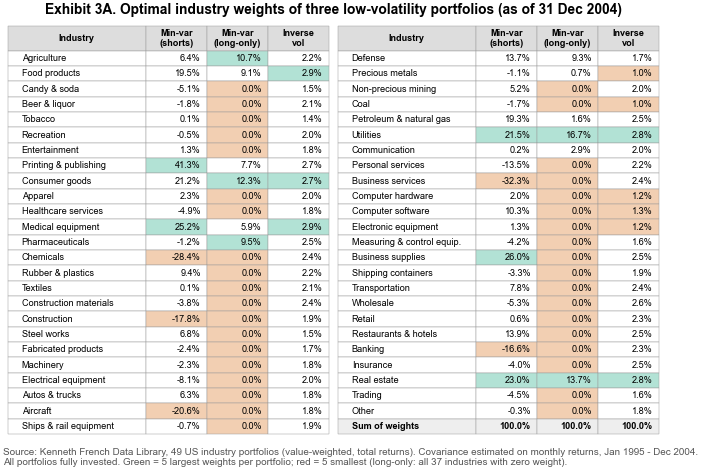

In [13]:
n_zero = int((W["mv_long_only"] == 0).sum())
HEAD = ["Industry", "Min-var\n(shorts)", "Min-var\n(long-only)", "Inverse\nvol"]

def half_table(ax, codes, with_sum=False):
    text, colors = [], []
    for c in codes:
        text.append([EN[c]] + [f"{W.at[c, k]:.1%}" for k in COLS])
        colors.append(["white"] + [fill_of(c, k) or "white" for k in COLS])
    if with_sum:
        text.append(["Sum of weights"] + [f"{W[k].sum():.1%}" for k in COLS])
        colors.append(["#EEEEEE"] * 4)
    tab = ax.table(cellText=text, colLabels=HEAD, cellColours=colors,
                   colColours=["#DDDDDD"] * 4, colWidths=[0.43, 0.19, 0.19, 0.19],
                   cellLoc="right", bbox=[0, 0, 1, 1])
    tab.auto_set_font_size(False)
    tab.set_fontsize(6)
    for (r, c), cell in tab.get_celld().items():
        cell.set_linewidth(0.3)
        cell.set_edgecolor("#999999")
        if c == 0:
            cell.set_text_props(ha="left")
            cell._loc = "left"
        if r == 0:
            cell.set_text_props(weight="bold", ha="center")
            cell.set_height(cell.get_height() * 1.6)
        if with_sum and r == len(text):
            cell.set_text_props(weight="bold")
    ax.axis("off")

fig, (axL, axR) = utils.new_fig("tall", 1, 2)
half_table(axL, W.index[:25])
half_table(axR, W.index[25:], with_sum=True)
fig.suptitle("Exhibit 3A. Optimal industry weights of three low-volatility portfolios (as of 31 Dec 2004)",
             fontsize=config.FONT_TITLE, fontweight="bold")
src = ("Source: Kenneth French Data Library, 49 US industry portfolios (value-weighted, total returns). "
       "Covariance estimated on monthly returns, Jan 1995 - Dec 2004.\n"
       "All portfolios fully invested. Green = 5 largest weights per portfolio; red = 5 smallest "
       f"(long-only: all {n_zero} industries with zero weight).")
path = utils.save_fig(fig, "fig_3A_weights_table", source=src)
print("PNG →", path.relative_to(ROOT))
plt.show()

### 8.2 权重分布对比图

把每个组合的 49 个权重**从大到小排序**后画成曲线（x 轴是排名，不是具体行业）。一眼就能看出三种方法的差别：

- **可做空**：曲线两头翘，左边是大额多头，右边掉到 0 以下的是空头；
- **只做多**：前几名很高，很快掉到 0 后一路持平（角点解）；
- **逆波动率**：一条接近水平的线，权重都在等权 1/49 附近。

这张图可以帮助报告解释第 7.1 节的表格，是否放进报告由你决定。

PNG → output\figures\fig_3A_weight_profile.png


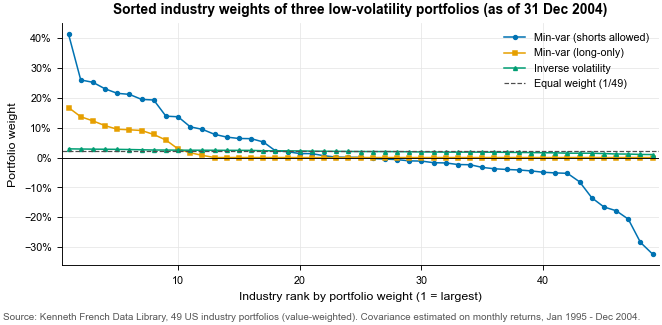

In [14]:
fig, ax = utils.new_fig("full")
rank = np.arange(1, n + 1)
styles = {"mv_short": dict(color=config.COLORS[0], marker="o"),
          "mv_long_only": dict(color=config.COLORS[1], marker="s"),
          "inverse_vol": dict(color=config.COLORS[2], marker="^")}
for k, label in COLS.items():
    ax.plot(rank, W[k].sort_values(ascending=False).to_numpy(), label=label,
            markersize=2.5, linewidth=1.0, **styles[k])
ax.axhline(0, color="black", linewidth=0.6)
ax.axhline(1 / n, color=config.COLOR_MARKET, linewidth=0.8, linestyle="--", label="Equal weight (1/49)")
ax.set_xlim(0.5, n + 0.5)
ax.set_xlabel("Industry rank by portfolio weight (1 = largest)")
ax.set_ylabel("Portfolio weight")
utils.percent_axis(ax, "y")
ax.set_title("Sorted industry weights of three low-volatility portfolios (as of 31 Dec 2004)")
ax.legend(loc="upper right")
path = utils.save_fig(fig, "fig_3A_weight_profile",
                      source="Source: Kenneth French Data Library, 49 US industry portfolios (value-weighted). "
                             "Covariance estimated on monthly returns, Jan 1995 - Dec 2004.")
print("PNG →", path.relative_to(ROOT))
plt.show()


### 备注

保存权重，供3B-3E的notebook直接读取（避免重复优化、保证各题用同一组权重）

In [15]:
# 保存权重，供 3B–3E 的 notebook 直接读取（避免重复优化、保证各题用同一组权重）
W.to_pickle(Path.cwd() / "weights_3A.pkl")
print("已保存 weights_3A.pkl 供 3B–3E 使用")

已保存 weights_3A.pkl 供 3B–3E 使用
